# Human Pose Classification from Wi-Fi CSI

## Project overview

This notebook investigates whether Wi-Fi Channel State Information (CSI) can identify 12 human poses and movements. It follows the complete workflow from raw MATLAB files to exploratory analysis, signal representation, model evaluation, and inference.

### Research question

Can a classifier distinguish a person's pose or movement from the way that motion changes the wireless channel over time?

### Dataset

The data come from the [Wi-Pose dataset](https://github.com/NjtechCVLab/Wi-PoseDataset). Each frame contains:

- **CSI:** five repeated measurements across 30 subcarriers and nine transmitter–receiver links.
- **SkeletonPoints:** 18 body joints used as an annotation and diagnostic reference.

The skeleton is not used as a model input. The final classifier receives CSI only, which avoids leaking the target through the body-joint annotation.

### Notebook structure

1. Prepare the raw MATLAB files and create a reusable pickle file.
2. Validate shapes, labels, and skeleton coordinates.
3. Explore distributions, variance, correlations, and noise.
4. Compare PCA, wavelet features, and unsupervised clusters.
5. Train sequence-level classifiers and evaluate them on held-out recordings.
6. Use the selected model for inference on a new CSI sequence.

In [1]:
%pip install mat73

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


# 1. Data Preparation

## Purpose

The source files are individual MATLAB files, one file per frame. Reopening more than 130,000 small files during every experiment would be slow, so this section parses the filenames, loads the two required arrays, validates each record, and stores the complete table as `dataset.pkl`.

The generated pickle is an intermediate artifact for this notebook. Only load pickle files from a trusted source because pickle can execute arbitrary Python code while loading.

In [2]:
import glob
import os
import re
import time
from concurrent.futures import ThreadPoolExecutor, as_completed

import mat73
import numpy as np
import pandas as pd
import scipy.io as sio
from tqdm.auto import tqdm

# File and variable configuration
DATA_DIR = "Wi-Pose/Train"
OUTPUT_PATH = "dataset.pkl"
CSI_VAR = "CSI"
SKELETON_VAR = "SkeletonPoints"

# Loading many small files is I/O-bound, so using more threads than CPU cores is reasonable.
N_WORKERS = min(32, (os.cpu_count() or 4) * 2)

# Example filename: bend_001-frame012.mat
FILE_PATTERN = re.compile(
    r"^(?P<pose>.+)_(?P<pose_no>\d+)-frame(?P<frame>\d+)\.mat$",
    re.IGNORECASE,
)

In [3]:
mat_paths = glob.glob(os.path.join(DATA_DIR, "**", "*.mat"), recursive=True)

index_rows = []
skipped_paths = []

for path in mat_paths:
    match = FILE_PATTERN.match(os.path.basename(path))
    if match is None:
        skipped_paths.append(path)
        continue

    index_rows.append({
        "pose": match["pose"],
        "pose_no": int(match["pose_no"]),
        "frame": int(match["frame"]),
        "path": path,
    })

if not index_rows:
    raise FileNotFoundError(f"No valid .mat files were found under {DATA_DIR!r}")

index_df = (
    pd.DataFrame(index_rows)
    .sort_values(["pose", "pose_no", "frame"])
    .reset_index(drop=True)
)

print(f"{len(index_df):,} files indexed; {len(skipped_paths):,} filenames skipped")
display(index_df.head())

132847 files indexed, 0 skipped (name did not match)


,pose,pose_no,frame,path
0,bend,1,1,Wi-Pose/Train\bend_001-frame001.mat
1,bend,1,2,Wi-Pose/Train\bend_001-frame002.mat
2,bend,1,3,Wi-Pose/Train\bend_001-frame003.mat
3,bend,1,4,Wi-Pose/Train\bend_001-frame004.mat
4,bend,1,5,Wi-Pose/Train\bend_001-frame005.mat


In [4]:
def load_mat(path):
    """Load CSI and skeleton arrays from a classic MAT file or a v7.3 HDF5 MAT file."""
    variables = [CSI_VAR, SKELETON_VAR]

    try:
        data = sio.loadmat(path, variable_names=variables)
    except (NotImplementedError, OSError, ValueError):
        data = mat73.loadmat(path, only_include=variables)

    missing = [name for name in variables if name not in data]
    if missing:
        raise KeyError(f"Missing variables {missing} in {path}")

    # Store amplitude consistently; phase is not used anywhere in this notebook.
    csi = np.abs(np.asarray(data[CSI_VAR])).astype(np.float32)
    skeleton = np.asarray(data[SKELETON_VAR], dtype=np.float32).reshape(-1)

    return csi, skeleton


# Fail early if the variable names or shapes do not match the dataset description.
sample_csi, sample_skeleton = load_mat(index_df.loc[0, "path"])
assert sample_csi.shape == (5, 30, 3, 3), sample_csi.shape
assert sample_skeleton.shape == (54,), sample_skeleton.shape
print("CSI:", sample_csi.shape, sample_csi.dtype)
print("Skeleton:", sample_skeleton.shape, sample_skeleton.dtype)

CSI: (5, 30, 3, 3) float32 | Skeleton: (54,) float32


In [ ]:
def load_record(row):
    """Load one indexed frame and return either a record or an error description."""
    try:
        csi, skeleton = load_mat(row["path"])
        record = {**row, "CSI": csi, "SkeletonPoints": skeleton}
        return record, None
    except Exception as exc:
        return None, (row["path"], repr(exc))


records = index_df.to_dict("records")
loaded_records = []
load_errors = []

started_at = time.time()
with ThreadPoolExecutor(max_workers=N_WORKERS) as executor:
    futures = [executor.submit(load_record, row) for row in records]
    for future in tqdm(as_completed(futures), total=len(futures), desc="Reading .mat files"):
        record, error = future.result()
        if record is not None:
            loaded_records.append(record)
        if error is not None:
            load_errors.append(error)

elapsed = time.time() - started_at
print(f"Loaded {len(loaded_records):,} files in {elapsed:.1f} seconds")
print(f"Failed files: {len(load_errors):,}")
if load_errors:
    print("First failures:", load_errors[:5])

# as_completed returns records in completion order, so restore chronological order.
dataset = (
    pd.DataFrame(loaded_records)
    .sort_values(["pose", "pose_no", "frame"])
    .reset_index(drop=True)
)
dataset.to_pickle(OUTPUT_PATH)
print(f"Saved {len(dataset):,} rows to {OUTPUT_PATH}")

### Interpretation

The previous run indexed and loaded **132,847 files with no filename or loading failures**. This confirms that the naming rule covers the dataset and that every frame contains the required variables. The explicit sort before saving is important: threaded loading finishes out of order, while every later time-series calculation assumes that frames are chronological.

If a future run reports failures, do not silently train on the partial table. Inspect `load_errors` first because missing frames can change the motion spectrum and sequence length.

# 2. Exploratory Data Analysis

## Data representation

This section reads `dataset.pkl`. Each row represents one frame and contains two measurements:

- **CSI**, shape `(5, 30, 3, 3)`: five repeated channel snapshots, 30 OFDM subcarriers, three transmitting antennas, and three receiving antennas.
- **SkeletonPoints**, shape `(54,)`: 18 x coordinates, followed by 18 y coordinates and 18 confidence scores.

The skeleton follows the OpenPose joint order: nose, neck, shoulders, elbows, wrists, hips, knees, ankles, eyes, and ears. The stored axes are swapped only for visualization so that the body appears upright; numerical features retain the original order.

### Questions answered in this section

1. Are the dimensions and labels internally consistent?
2. Is the dataset balanced by pose and sequence length?
3. Which CSI links and body joints contain reliable variation?
4. How redundant are the subcarriers and antenna links?
5. Does denoising improve readability without creating leakage?

## Setup


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display
from scipy.ndimage import median_filter
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

df = pd.read_pickle("dataset.pkl")
df = df.sort_values(["pose", "pose_no", "frame"]).reset_index(drop=True)

N_PKT, N_SUB, N_TX, N_RX = 5, 30, 3, 3
N_JOINTS = 18
N_LINKS = N_TX * N_RX
CSI_DIM = N_SUB * N_LINKS          # one frame after the 5 packets are averaged
SKEL_DIM = N_JOINTS * 2            # x and y only; confidence is a quality flag
CONF_MIN = 0.1
RANDOM_STATE = 0

JOINT_NAMES = [
    "nose", "neck", "R_sho", "R_elb", "R_wri", "L_sho", "L_elb", "L_wri",
    "R_hip", "R_knee", "R_ank", "L_hip", "L_knee", "L_ank",
    "R_eye", "L_eye", "R_ear", "L_ear",
]
BONES = [
    (1, 2), (1, 5), (2, 3), (3, 4), (5, 6), (6, 7),
    (1, 8), (8, 9), (9, 10), (1, 11), (11, 12), (12, 13),
    (1, 0), (0, 14), (14, 16), (0, 15), (15, 17),
]
NECK, R_SHO, L_SHO, R_HIP, L_HIP = 1, 2, 5, 8, 11
LINK_NAMES = [f"Tx{tx}-Rx{rx}" for tx in range(1, N_TX + 1) for rx in range(1, N_RX + 1)]

print(f"{len(df):,} frames | {df.groupby(['pose', 'pose_no']).ngroups:,} sequences | {df['pose'].nunique()} poses")
print("poses:", ", ".join(sorted(df["pose"].unique())))


132,847 frames | 1,152 sequences | 12 poses
poses: bend, circle, crouch, jump, pull, push, run, sitdown, standup, throw, walk, wave


In [2]:
def build_matrices(frame_df):
    """Packet-averaged CSI (N, 270) and joints (N, 18, 3) in stored order."""
    n = len(frame_df)
    X_csi = np.empty((n, CSI_DIM), dtype=np.float32)
    csi_values = frame_df["CSI"].to_numpy()
    for start in range(0, n, 8000):
        stop = min(start + 8000, n)
        batch = np.stack([
            np.asarray(v, dtype=np.float32).reshape(N_PKT, N_SUB, N_TX, N_RX)
            for v in csi_values[start:stop]
        ])
        X_csi[start:stop] = batch.mean(axis=1).reshape(stop - start, -1)

    skeleton = np.stack(frame_df["SkeletonPoints"].to_numpy()).astype(np.float32)
    # (N, 3, 18) blocks are x, y, confidence -> (N, 18, 3)
    joints = skeleton.reshape(n, 3, N_JOINTS).transpose(0, 2, 1)
    return X_csi, joints


def visible_joints(kp):
    return (kp[:, 2] >= CONF_MIN) & np.isfinite(kp[:, :2]).all(axis=1)


def plot_skeleton(kp, ax, color="tab:blue", label=False, alpha=1.0):
    """Draw one frame. Display swaps stored (body axis, shoulder axis) so the person stands upright."""
    ok = visible_joints(kp)
    horiz, vert = kp[:, 1], kp[:, 0]
    if np.any(~ok):
        ax.scatter(horiz[~ok], vert[~ok], s=16, color="0.75", alpha=alpha, zorder=2)
    ax.scatter(horiz[ok], vert[ok], s=22, color=color, alpha=alpha, zorder=3)
    for a, b in BONES:
        if ok[a] and ok[b]:
            ax.plot(horiz[[a, b]], vert[[a, b]], color=color, lw=1.8, alpha=alpha, zorder=2)
    if label:
        for i in np.where(ok)[0]:
            ax.text(horiz[i], vert[i], f"{i}:{JOINT_NAMES[i]}", fontsize=7)
    ax.set_aspect("equal")


def sequence_limits(seq, pad=30):
    ok = (seq[..., 2] >= CONF_MIN) & np.isfinite(seq[..., :2]).all(axis=-1)
    horiz = seq[..., 1][ok]
    vert = seq[..., 0][ok]
    if horiz.size == 0:
        return (0, 1), (1, 0)
    return (
        (float(horiz.min() - pad), float(horiz.max() + pad)),
        (float(vert.max() + pad), float(vert.min() - pad)),
    )


def normalize_skeleton(joints):
    """Neck-centered, torso-scaled (x, y). Low-confidence joints are imputed with the kept-frame mean.

    Returns X_skel (N, 36) and a boolean mask of frames with a reliable neck and scale.
    """
    xy = joints[..., :2].astype(np.float64)
    valid = joints[..., 2] >= CONF_MIN
    centered = xy - xy[:, NECK, :][:, None, :]

    hip_mid = (xy[:, R_HIP, :] + xy[:, L_HIP, :]) / 2.0
    torso = np.linalg.norm(hip_mid - xy[:, NECK, :], axis=1)
    shoulder = np.linalg.norm(xy[:, R_SHO, :] - xy[:, L_SHO, :], axis=1)
    hip_ok = valid[:, NECK] & valid[:, R_HIP] & valid[:, L_HIP]
    shoulder_ok = valid[:, NECK] & valid[:, R_SHO] & valid[:, L_SHO]
    scale = np.where(hip_ok, torso, np.where(shoulder_ok, shoulder, np.nan))
    keep = np.isfinite(scale) & (scale > 1.0) & (valid.sum(axis=1) >= 12)

    normed = np.full_like(centered, np.nan)
    np.divide(centered, scale[:, None, None], out=normed, where=keep[:, None, None])
    normed[~valid] = np.nan
    flat = normed.reshape(len(normed), -1)
    means = np.nanmean(flat[keep], axis=0)
    means = np.where(np.isfinite(means), means, 0.0)
    missing = np.isnan(flat)
    flat[missing] = np.take(means, np.where(missing)[1])
    return flat.astype(np.float32), keep


def separation_ratio(scores, labels, n_components):
    """Between-class scatter divided by within-class scatter on the first PCs."""
    xy = np.asarray(scores)[:, :n_components]
    labels = np.asarray(labels)
    center = xy.mean(axis=0)
    between = 0.0
    within = 0.0
    for lab in np.unique(labels):
        block = xy[labels == lab]
        between += len(block) * np.sum((block.mean(axis=0) - center) ** 2)
        within += np.sum((block - block.mean(axis=0)) ** 2)
    return float(between / max(within, 1e-8))


def components_for(ratio, levels=(0.80, 0.90, 0.95)):
    cumulative = np.cumsum(ratio)
    rows = []
    for level in levels:
        if cumulative[-1] < level:
            reached = f"above {len(cumulative)} components ({cumulative[-1]:.1%})"
            rows.append({"variance": f"{level:.0%}", "components": reached})
        else:
            k = int(np.searchsorted(cumulative, level) + 1)
            rows.append({
                "variance": f"{level:.0%}",
                "components": f"{k} (actual {cumulative[k - 1]:.1%})",
            })
    return pd.DataFrame(rows)


## 1. Feature and dimension analysis

CSI is already a real, non-negative amplitude. A frame feature averages the 5 packets, leaving 30 subcarriers × 9 antenna links = **270** numbers. The 5 packets are repeated measures of one image, so the average is the frame descriptor used in the rest of this notebook.

The skeleton frame keeps all 18 joints as `(x, y, confidence)`. Pose geometry later uses the 36 coordinates. Confidence decides which joints are trustworthy.


In [3]:
X_csi, joints = build_matrices(df)
seq_index = df.groupby(["pose", "pose_no"], sort=False).indices

sample = np.asarray(df["SkeletonPoints"].iloc[0], dtype=np.float32).reshape(3, N_JOINTS)
block_ranges = pd.DataFrame({
    "block": ["x (18,)", "y (18,)", "confidence (18,)"],
    "min": sample.min(axis=1).round(2),
    "max": sample.max(axis=1).round(2),
    "mean": sample.mean(axis=1).round(2),
})

overview = pd.DataFrame({
    "item": [
        "Frames",
        "Sequences (pose, pose_no)",
        "Pose classes",
        "CSI stored shape",
        "CSI frame feature",
        "Skeleton stored shape",
        "Skeleton tensor used below",
        "Confidence below 0.1",
    ],
    "value": [
        f"{len(df):,}",
        f"{len(seq_index):,}",
        f"{df['pose'].nunique()}",
        "(5 packets, 30 subcarriers, 3 Tx, 3 Rx)",
        f"{X_csi.shape} amplitude, mean {X_csi.mean():.2f}, std {X_csi.std():.2f}",
        "(54,) = x[18] + y[18] + confidence[18]",
        f"{joints.shape} columns [x, y, confidence]",
        f"{(joints[..., 2] < CONF_MIN).mean():.1%} of joint detections",
    ],
})

display(overview)
print("Frame 0 stored as three blocks of 18:")
display(block_ranges)
print(
    f"All frames | x {joints[..., 0].min():.0f}–{joints[..., 0].max():.0f}, "
    f"y {joints[..., 1].min():.0f}–{joints[..., 1].max():.0f}, "
    f"confidence {joints[..., 2].min():.3f}–{joints[..., 2].max():.3f}"
)
print("First-frame joint check (stored x, y, confidence):")
print(pd.DataFrame(joints[0], columns=["x", "y", "confidence"], index=JOINT_NAMES).round(2).T)


,item,value
0,Frames,"132,847"
1,"Sequences (pose, pose_no)","1,152"
2,Pose classes,12
3,CSI stored shape,"(5 packets, 30 subcarriers, 3 Tx, 3 Rx)"
4,CSI frame feature,"(132847, 270) amplitude, mean 17.85, std 11.05"
5,Skeleton stored shape,"(54,) = x[18] + y[18] + confidence[18]"
6,Skeleton tensor used below,"(132847, 18, 3) columns [x, y, confidence]"
7,Confidence below 0.1,9.5% of joint detections


Frame 0 stored as three blocks of 18:


,block,min,max,mean
0,"x (18,)",121.330002,548.789978,304.010010
1,"y (18,)",288.470001,362.970001,328.420013
2,"confidence (18,)",0.010000,0.940000,0.590000


All frames | x 25–632, y -85–489, confidence 0.001–1.159
First-frame joint check (stored x, y, confidence):
                  nose        neck       R_sho       R_elb       R_wri  \
x           141.490005  199.880005  198.550003  280.609985  357.640015   
y           288.470001  339.029999  360.390015  362.970001  323.239990   
confidence    0.860000    0.660000    0.720000    0.870000    0.850000   

                 L_sho       L_elb       L_wri       R_hip      R_knee  \
x           201.210007  270.890015  353.809998  344.859985  446.959991   
y           317.670013  298.390015  296.709991  350.709991  338.140015   
confidence    0.600000    0.310000    0.370000    0.490000    0.720000   

                 R_ank       L_hip      L_knee       L_ank       R_eye  \
x           548.789978  331.940002  436.859985  536.830017  126.620003   
y           362.799988  316.070007  327.790009  355.089996  298.399994   
confidence    0.710000    0.390000    0.620000    0.480000    0.910000   

 

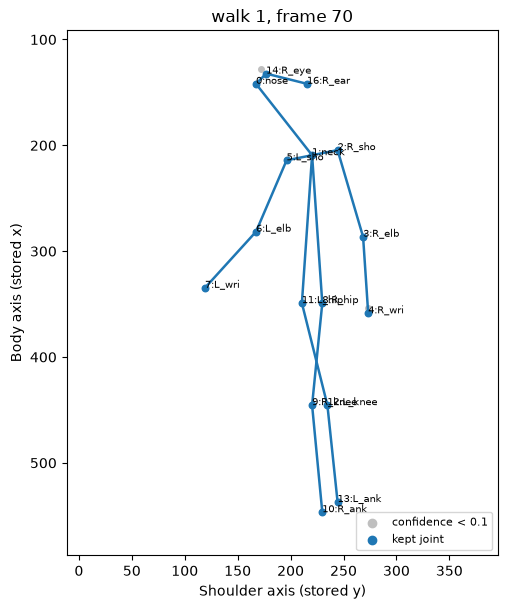

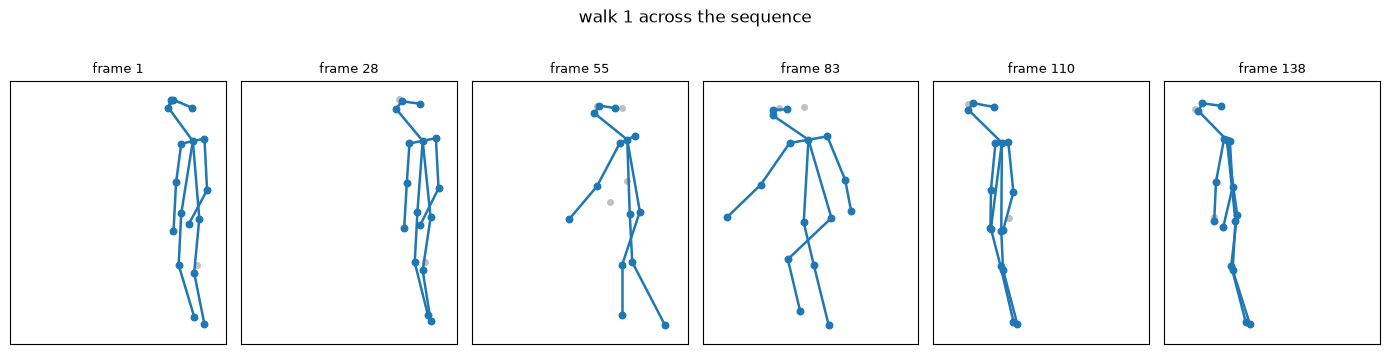

In [4]:
# One labeled frame, then six frames from the same walk. Grey points are confidence < 0.1.
demo_key = ("walk", 1)
demo_idx = np.sort(seq_index[demo_key])
limits = sequence_limits(joints[demo_idx])
mid = demo_idx[len(demo_idx) // 2]

fig, ax = plt.subplots(figsize=(5.2, 6.2))
plot_skeleton(joints[mid], ax, label=True)
ax.set_xlim(*limits[0])
ax.set_ylim(*limits[1])
ax.set_title(f"walk 1, frame {int(df.loc[mid, 'frame'])}")
ax.set_xlabel("Shoulder axis (stored y)")
ax.set_ylabel("Body axis (stored x)")
ax.scatter([], [], color="0.75", label=f"confidence < {CONF_MIN}")
ax.scatter([], [], color="tab:blue", label="kept joint")
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.show()

picks = np.linspace(0, len(demo_idx) - 1, 6, dtype=int)
fig, axes = plt.subplots(1, 6, figsize=(14, 3.6))
for ax, t in zip(axes, picks):
    row = demo_idx[t]
    plot_skeleton(joints[row], ax)
    ax.set_xlim(*limits[0])
    ax.set_ylim(*limits[1])
    ax.set_title(f"frame {int(df.loc[row, 'frame'])}", fontsize=9)
    ax.set_xticks([])
    ax.set_yticks([])
fig.suptitle("walk 1 across the sequence", y=1.02)
plt.tight_layout()
plt.show()


### Interpretation

The dataset contains **132,847 frames, 1,152 sequences, and 12 poses**. Averaging the five within-frame CSI repetitions produces 270 features per frame. About **9.5% of joint detections** fall below the confidence threshold, so confidence-aware masking is necessary for skeleton statistics.

The skeleton plot is also a schema check. A recognizable body confirms that the 54 stored values were reshaped correctly as three blocks of 18; reshaping them directly to `(18, 3)` would mix joints and coordinates.

### Optional sequence animation

The static strip above is the layout check. Run the next cell when you want the full sequence.


In [5]:
def animate_sequence(pose, pose_no, interval=60):
    idx = np.sort(seq_index[(pose, pose_no)])
    seq = joints[idx]
    limits = sequence_limits(seq)
    frames = df.loc[idx, "frame"].to_numpy()
    fig, ax = plt.subplots(figsize=(4.6, 5.6))

    def update(i):
        ax.clear()
        plot_skeleton(seq[i], ax)
        ax.set_xlim(*limits[0])
        ax.set_ylim(*limits[1])
        ax.set_title(f"{pose} {pose_no}  frame {int(frames[i])}")

    anim = FuncAnimation(fig, update, frames=len(seq), interval=interval)
    plt.close(fig)
    return HTML(anim.to_jshtml())


In [6]:
animate_sequence("walk", 1)


## 2. Distribution, variance, and correlation

Sequence counts are the right unit for class balance, because every pose was recorded as 96 sequences. Frame counts still differ, since sequences are not the same length. CSI plots use the 270-dimensional packet average. Skeleton plots ignore joints with confidence below 0.1 so a missed detection does not look like a large movement.


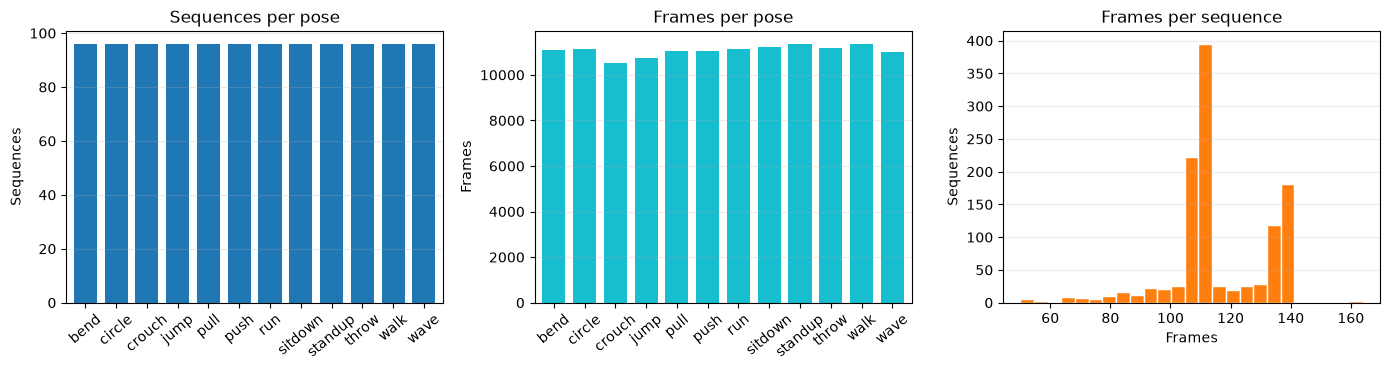

,count,mean,std,min,25%,50%,75%,max
frames per sequence,1152.0,115.3,16.1,50.0,109.0,110.0,134.0,164.0


In [7]:
pose_order = sorted(df["pose"].unique())
frames_per_pose = df.groupby("pose").size().reindex(pose_order)
seqs_per_pose = df.groupby("pose")["pose_no"].nunique().reindex(pose_order)
lengths = df.groupby(["pose", "pose_no"]).size()

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
seqs_per_pose.plot(kind="bar", ax=axes[0], width=0.75, color="tab:blue")
axes[0].set_title("Sequences per pose")
axes[0].set_xlabel("")
axes[0].set_ylabel("Sequences")
axes[0].tick_params(axis="x", rotation=40)

frames_per_pose.plot(kind="bar", ax=axes[1], width=0.75, color="tab:cyan")
axes[1].set_title("Frames per pose")
axes[1].set_xlabel("")
axes[1].set_ylabel("Frames")
axes[1].tick_params(axis="x", rotation=40)

axes[2].hist(lengths, bins=25, color="tab:orange", edgecolor="white")
axes[2].set_title("Frames per sequence")
axes[2].set_xlabel("Frames")
axes[2].set_ylabel("Sequences")
for ax in axes:
    ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

display(lengths.describe().round(1).to_frame("frames per sequence").T)


### Interpretation

Every pose has the same number of sequences, so the **class labels are balanced at the sequence level**. Sequence duration is not perfectly balanced: the median is 110 frames, with a range of 50–164. Models should therefore use fixed-length summaries, padding/masking, or temporal pooling rather than treating every frame as an independent sample.

The correct split unit is a complete sequence, not a frame. A random frame split would place nearly identical neighboring frames from one recording in both training and test data and would overstate performance.

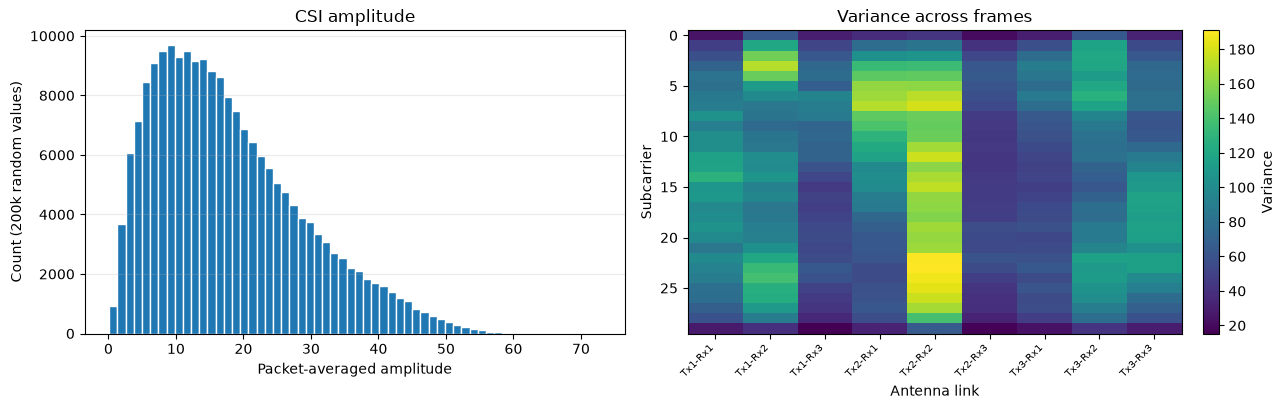

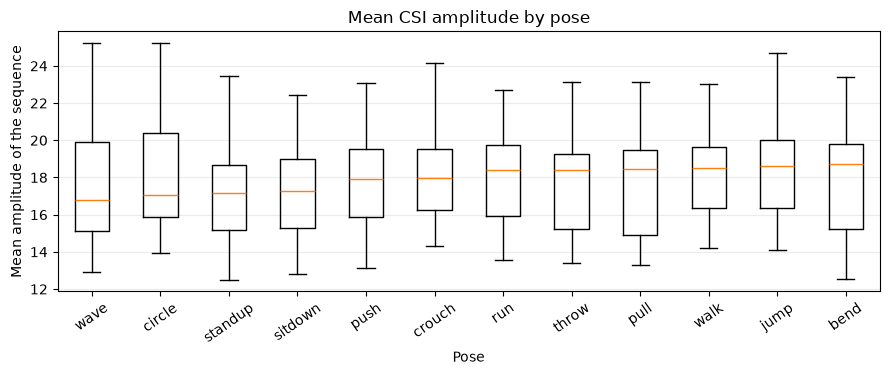

Highest-variance subcarrier / link pairs:
  1. subcarrier 23, Tx2-Rx2, variance 191.0
  2. subcarrier 22, Tx2-Rx2, variance 189.8
  3. subcarrier 24, Tx2-Rx2, variance 187.3
  4. subcarrier 25, Tx2-Rx2, variance 183.7
  5. subcarrier  7, Tx2-Rx2, variance 180.0


In [8]:
rng = np.random.default_rng(RANDOM_STATE)
amplitude_sample = X_csi.ravel()
amplitude_sample = amplitude_sample[rng.choice(amplitude_sample.size, size=200_000, replace=False)]
link_variance = X_csi.var(axis=0).reshape(N_SUB, N_LINKS)

seq_amplitude = []
for (pose, pose_no), idx in seq_index.items():
    seq_amplitude.append({"pose": pose, "amplitude": float(X_csi[np.sort(idx)].mean())})
seq_amplitude = pd.DataFrame(seq_amplitude)
amp_order = seq_amplitude.groupby("pose")["amplitude"].median().sort_values().index

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
axes[0].hist(amplitude_sample, bins=60, color="tab:blue", edgecolor="white")
axes[0].set_title("CSI amplitude")
axes[0].set_xlabel("Packet-averaged amplitude")
axes[0].set_ylabel("Count (200k random values)")
axes[0].grid(axis="y", alpha=0.25)

image = axes[1].imshow(link_variance, aspect="auto", cmap="viridis")
axes[1].set_title("Variance across frames")
axes[1].set_xlabel("Antenna link")
axes[1].set_ylabel("Subcarrier")
axes[1].set_xticks(range(N_LINKS))
axes[1].set_xticklabels(LINK_NAMES, rotation=45, ha="right", fontsize=7)
fig.colorbar(image, ax=axes[1], fraction=0.046, pad=0.04, label="Variance")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(9, 4))
ordered = [seq_amplitude.loc[seq_amplitude["pose"] == pose, "amplitude"].to_numpy() for pose in amp_order]
ax.boxplot(ordered, showfliers=False)
ax.set_xticklabels(list(amp_order))
ax.set_title("Mean CSI amplitude by pose")
ax.set_xlabel("Pose")
ax.set_ylabel("Mean amplitude of the sequence")
ax.tick_params(axis="x", rotation=35)
ax.grid(axis="y", alpha=0.25)
plt.suptitle("")
plt.tight_layout()
plt.show()

flat_var = link_variance.ravel()
top = np.argsort(flat_var)[-5:][::-1]
print("Highest-variance subcarrier / link pairs:")
for rank, j in enumerate(top, start=1):
    print(f"  {rank}. subcarrier {j // N_LINKS:2d}, {LINK_NAMES[j % N_LINKS]}, variance {flat_var[j]:.1f}")


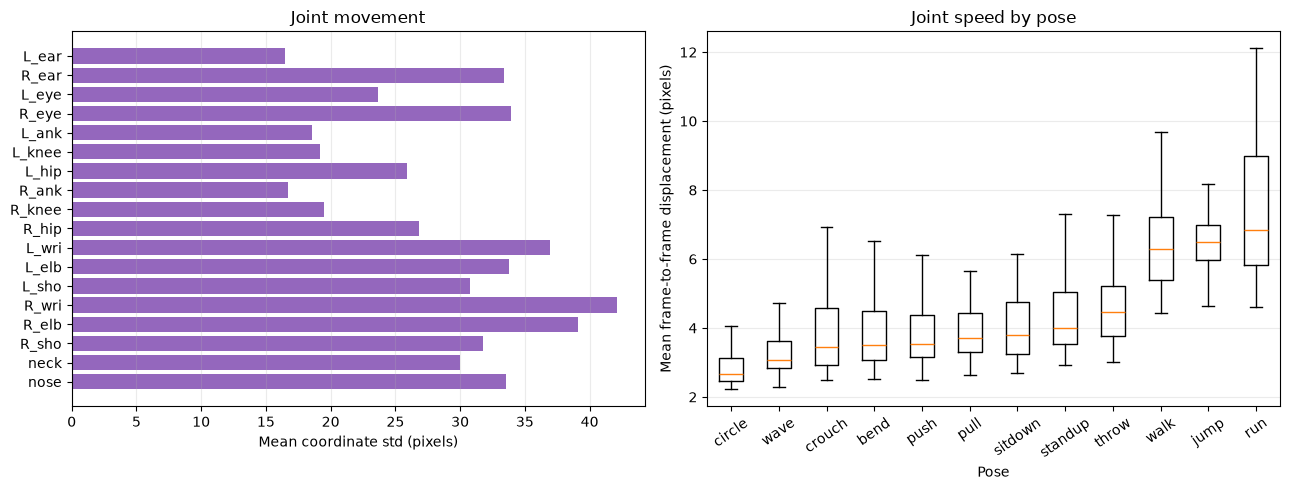

Lowest joint visibility (confidence >= 0.1):
L_ear    25.5%
L_eye    54.9%
L_wri    80.5%
L_elb    82.6%
L_ank    96.9%


In [9]:
confidence_rate = (joints[..., 2] >= CONF_MIN).mean(axis=0)
variability = np.full(N_JOINTS, np.nan)
for joint in range(N_JOINTS):
    spread = []
    for idx in seq_index.values():
        idx = np.sort(idx)
        mask = joints[idx, joint, 2] >= CONF_MIN
        pts = joints[idx, joint, :2][mask]
        if len(pts) >= 5:
            spread.append(pts.std(axis=0).mean())
    variability[joint] = np.mean(spread)

motion_rows = []
for (pose, pose_no), idx in seq_index.items():
    idx = np.sort(idx)
    xy = joints[idx, :, :2]
    valid = joints[idx, :, 2] >= CONF_MIN
    displacement = np.linalg.norm(np.diff(xy, axis=0), axis=2)
    both = valid[:-1] & valid[1:]
    if np.any(both):
        motion_rows.append({"pose": pose, "motion": float(displacement[both].mean())})
motion_df = pd.DataFrame(motion_rows)
motion_order = motion_df.groupby("pose")["motion"].median().sort_values().index

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
y_pos = np.arange(N_JOINTS)
axes[0].barh(y_pos, variability, color="tab:purple")
axes[0].set_yticks(y_pos)
axes[0].set_yticklabels(JOINT_NAMES)
axes[0].set_xlabel("Mean coordinate std (pixels)")
axes[0].set_title("Joint movement")
axes[0].grid(axis="x", alpha=0.25)

ordered_motion = [motion_df.loc[motion_df["pose"] == pose, "motion"].to_numpy() for pose in motion_order]
axes[1].boxplot(ordered_motion, showfliers=False)
axes[1].set_xticklabels(list(motion_order))
axes[1].set_title("Joint speed by pose")
axes[1].set_xlabel("Pose")
axes[1].set_ylabel("Mean frame-to-frame displacement (pixels)")
axes[1].tick_params(axis="x", rotation=35)
axes[1].grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

visible = pd.Series(confidence_rate, index=JOINT_NAMES).sort_values()
print("Lowest joint visibility (confidence >= 0.1):")
print(visible.head(5).map(lambda v: f"{v:.1%}").to_string())


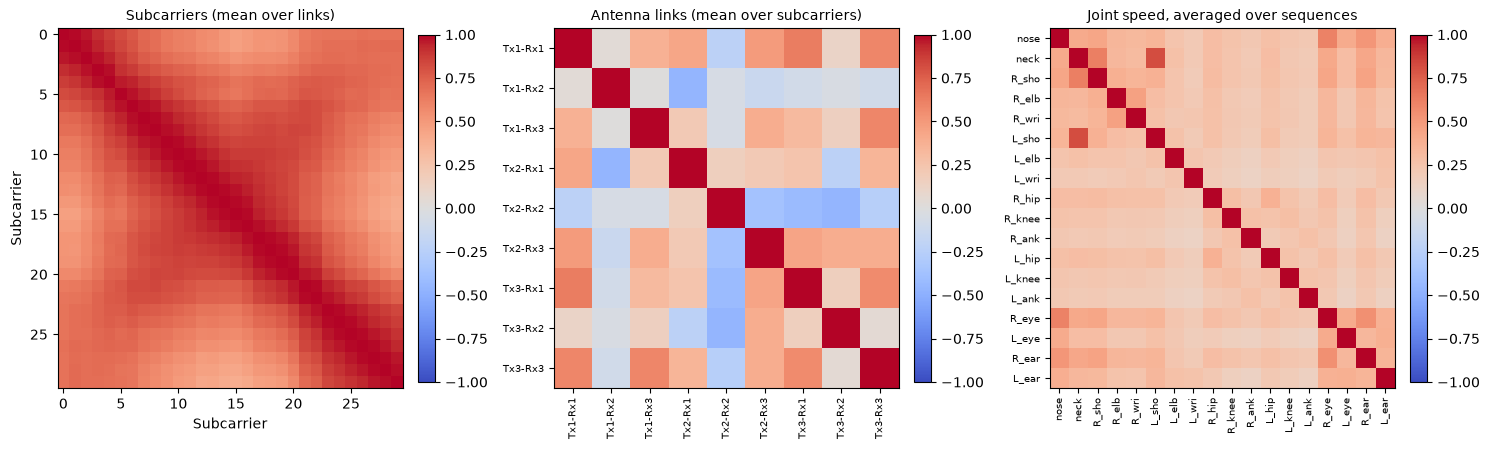

Adjacent subcarriers correlate at 0.98; subcarriers 10 apart correlate at 0.65.
Antenna-link correlation, off diagonal: mean 0.12, min -0.46, max 0.63.


In [10]:
# Correlation of the representation we will actually model.
subcarrier_signal = X_csi.reshape(-1, N_SUB, N_LINKS).mean(axis=2)
link_signal = X_csi.reshape(-1, N_SUB, N_LINKS).mean(axis=1)
subcarrier_corr = np.corrcoef(subcarrier_signal, rowvar=False)
link_corr = np.corrcoef(link_signal, rowvar=False)

movement_corr_sum = np.zeros((N_JOINTS, N_JOINTS))
movement_corr_weight = np.zeros((N_JOINTS, N_JOINTS))
for idx in seq_index.values():
    idx = np.sort(idx)
    xy = joints[idx, :, :2]
    valid = joints[idx, :, 2] >= CONF_MIN
    displacement = np.linalg.norm(np.diff(xy, axis=0), axis=2)
    both = valid[:-1] & valid[1:]
    observed = np.where(both, displacement, 0.0)
    count = both.sum(axis=0)
    center = observed.sum(axis=0) / np.maximum(count, 1)
    centered = np.where(both, displacement - center, 0.0)
    overlap = both.T.astype(np.float64) @ both.astype(np.float64)
    covariance = centered.T @ centered
    variance = np.diag(covariance)
    denom = np.sqrt(variance[:, None] * variance[None, :])
    good = (overlap >= 8) & (denom > 1e-8)
    corr = np.zeros((N_JOINTS, N_JOINTS))
    corr[good] = covariance[good] / denom[good]
    movement_corr_sum[good] += corr[good]
    movement_corr_weight[good] += 1

movement_corr = movement_corr_sum / np.maximum(movement_corr_weight, 1)
np.fill_diagonal(subcarrier_corr, 1)
np.fill_diagonal(link_corr, 1)
np.fill_diagonal(movement_corr, 1)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
panels = [
    (axes[0], subcarrier_corr, "Subcarriers (mean over links)"),
    (axes[1], link_corr, "Antenna links (mean over subcarriers)"),
    (axes[2], movement_corr, "Joint speed, averaged over sequences"),
]
for ax, matrix, title in panels:
    image = ax.imshow(matrix, vmin=-1, vmax=1, cmap="coolwarm", aspect="auto")
    ax.set_title(title, fontsize=10)
    fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04)
axes[0].set_xlabel("Subcarrier")
axes[0].set_ylabel("Subcarrier")
axes[1].set_xticks(range(N_LINKS))
axes[1].set_yticks(range(N_LINKS))
axes[1].set_xticklabels(LINK_NAMES, rotation=90, fontsize=7)
axes[1].set_yticklabels(LINK_NAMES, fontsize=7)
axes[2].set_xticks(range(N_JOINTS))
axes[2].set_yticks(range(N_JOINTS))
axes[2].set_xticklabels(JOINT_NAMES, rotation=90, fontsize=7)
axes[2].set_yticklabels(JOINT_NAMES, fontsize=7)
plt.tight_layout()
plt.show()

neighbor = np.mean([subcarrier_corr[i, i + 1] for i in range(N_SUB - 1)])
distant = subcarrier_corr[np.triu_indices(N_SUB, k=10)].mean()
print(f"Adjacent subcarriers correlate at {neighbor:.2f}; subcarriers 10 apart correlate at {distant:.2f}.")
off_diag = link_corr[np.triu_indices(N_LINKS, k=1)]
print(f"Antenna-link correlation, off diagonal: mean {off_diag.mean():.2f}, min {off_diag.min():.2f}, max {off_diag.max():.2f}.")


### Interpretation

The signal contains two different structures:

- Adjacent subcarriers are extremely redundant (mean correlation about **0.98**), so averaging or dimensionality reduction across frequency is justified.
- Antenna links are much less redundant (mean off-diagonal correlation about **0.12**), so retaining all nine links preserves distinct propagation paths.

The highest variance occurs mainly around subcarriers 22–25 on Tx2–Rx2, but variance alone does not prove pose relevance; it may also reflect channel gain or environmental noise. On the skeleton side, the left ear and left eye have the lowest visibility, so face landmarks should not dominate conclusions about body motion.

## 3. Noise reduction

Two different kinds of noise show up in this data.

The 5 CSI packets on a frame disagree by a small amount. Their mean is the noise reduction used for every CSI feature above and for PCA. Averaging them does not mix neighboring frames.

A short moving average along a sequence, and a median filter on the skeleton, make the traces easier to read. Those filters mix adjacent frames, so they stay in this section as a check and are not the PCA input. Skeleton PCA instead drops coordinates with confidence below 0.1.


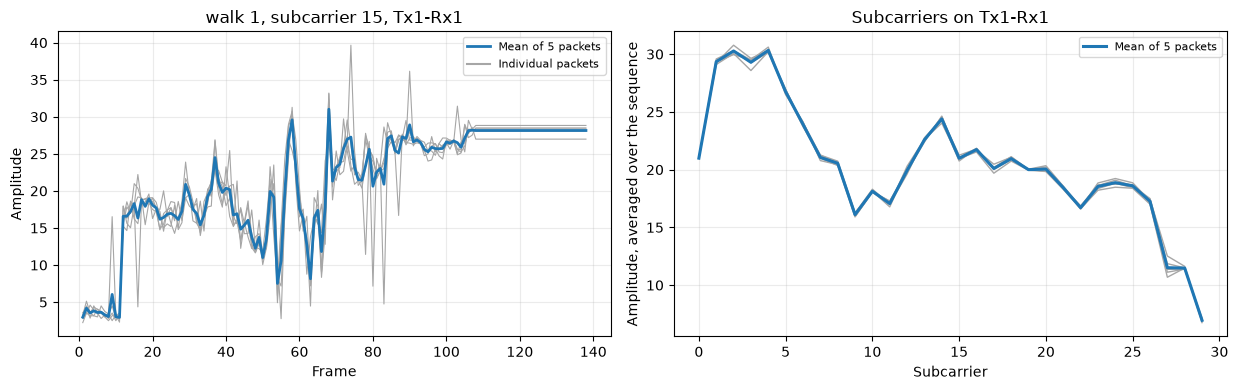

Mean std among the 5 packets: 1.69
Std of the packet-averaged CSI across frames of this sequence: 9.89
The packet mean is X_csi. Later sections use that matrix and do not average across frames.


In [11]:
# Within one frame the 5 packets are repeats. Compare them with their mean on walk 1.
packet_rows = []
for row_id in demo_idx:
    packet_rows.append(np.asarray(df["CSI"].iloc[row_id], dtype=np.float32).reshape(N_PKT, N_SUB, N_TX, N_RX))
packets = np.stack(packet_rows)   # (frames, 5, 30, 3, 3)
subcarrier, tx, rx = 15, 0, 0
trace = packets[:, :, subcarrier, tx, rx]
packet_mean = trace.mean(axis=1)
frame_numbers = df.loc[demo_idx, "frame"].to_numpy()

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4))
for packet in range(N_PKT):
    axes[0].plot(frame_numbers, trace[:, packet], color="0.65", lw=0.8)
axes[0].plot(frame_numbers, packet_mean, color="tab:blue", lw=2.0, label="Mean of 5 packets")
axes[0].plot([], [], color="0.65", label="Individual packets")
axes[0].set_title(f"walk 1, subcarrier {subcarrier}, {LINK_NAMES[tx * N_RX + rx]}")
axes[0].set_xlabel("Frame")
axes[0].set_ylabel("Amplitude")
axes[0].legend(fontsize=8)
axes[0].grid(alpha=0.25)

# Same comparison across subcarriers, averaged over the sequence.
per_sub = packets[:, :, :, tx, rx].mean(axis=0)   # (5, 30)
axes[1].plot(per_sub.T, color="0.65", lw=1)
axes[1].plot(per_sub.mean(axis=0), color="tab:blue", lw=2.2, label="Mean of 5 packets")
axes[1].set_title(f"Subcarriers on {LINK_NAMES[tx * N_RX + rx]}")
axes[1].set_xlabel("Subcarrier")
axes[1].set_ylabel("Amplitude, averaged over the sequence")
axes[1].legend(fontsize=8)
axes[1].grid(alpha=0.25)
plt.tight_layout()
plt.show()

within_frame = packets.std(axis=1).mean()
across_frames = X_csi[demo_idx].std()
print(f"Mean std among the 5 packets: {within_frame:.2f}")
print(f"Std of the packet-averaged CSI across frames of this sequence: {across_frames:.2f}")
print("The packet mean is X_csi. Later sections use that matrix and do not average across frames.")


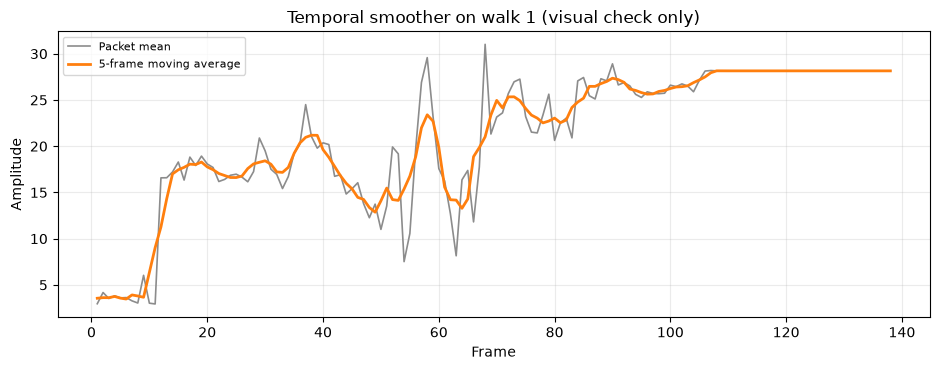

Mean frame-to-frame change: packet mean 1.69, moving average 0.60.
This smoother is not applied to X_csi.


In [12]:
window = 5
smoothed = pd.Series(packet_mean).rolling(window, center=True, min_periods=1).mean().to_numpy()
raw_step = np.abs(np.diff(packet_mean)).mean()
smooth_step = np.abs(np.diff(smoothed)).mean()

fig, ax = plt.subplots(figsize=(9.5, 3.8))
ax.plot(frame_numbers, packet_mean, color="0.55", lw=1.2, label="Packet mean")
ax.plot(frame_numbers, smoothed, color="tab:orange", lw=2.0, label=f"{window}-frame moving average")
ax.set_title("Temporal smoother on walk 1 (visual check only)")
ax.set_xlabel("Frame")
ax.set_ylabel("Amplitude")
ax.legend(fontsize=8)
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()
print(f"Mean frame-to-frame change: packet mean {raw_step:.2f}, moving average {smooth_step:.2f}.")
print("This smoother is not applied to X_csi.")


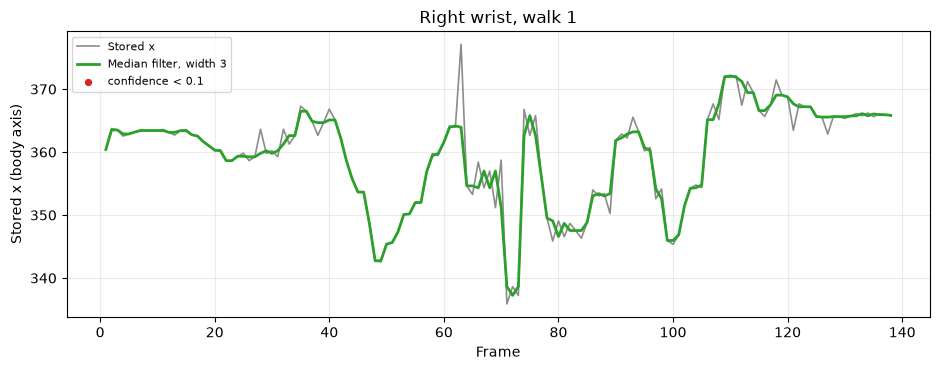

Jumps larger than 40 px, confident joints only: raw 0.51%, median filter 0.28%.
Low-confidence joints on this sequence: 12.4%.
PCA drops those coordinates. It does not use the median-filtered curve.


In [13]:
joint = JOINT_NAMES.index("R_wri")
raw_xy = joints[demo_idx, :, :2].astype(np.float64)
filtered_xy = median_filter(raw_xy, size=(3, 1, 1))
conf = joints[demo_idx, :, 2]
valid = conf >= CONF_MIN

def jump_rate(coords, mask, limit=40):
    step = np.linalg.norm(np.diff(coords, axis=0), axis=2)
    usable = mask[:-1] & mask[1:]
    return float((step[usable] > limit).mean()) if np.any(usable) else np.nan

fig, ax = plt.subplots(figsize=(9.5, 3.8))
ax.plot(frame_numbers, raw_xy[:, joint, 0], color="0.55", lw=1.2, label="Stored x")
ax.plot(frame_numbers, filtered_xy[:, joint, 0], color="tab:green", lw=2.0, label="Median filter, width 3")
low = ~valid[:, joint]
ax.scatter(frame_numbers[low], raw_xy[low, joint, 0], s=18, color="tab:red", zorder=3, label=f"confidence < {CONF_MIN}")
ax.set_title("Right wrist, walk 1")
ax.set_xlabel("Frame")
ax.set_ylabel("Stored x (body axis)")
ax.legend(fontsize=8)
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

print(f"Jumps larger than 40 px, confident joints only: raw {jump_rate(raw_xy, valid):.2%}, median filter {jump_rate(filtered_xy, valid):.2%}.")
print(f"Low-confidence joints on this sequence: {(~valid).mean():.1%}.")
print("PCA drops those coordinates. It does not use the median-filtered curve.")


### Interpretation

Averaging the five repeated packets reduces within-frame noise without mixing time steps, so it is safe for the model input. The five-frame moving average and skeleton median filter make plots smoother, but they combine neighboring frames and are used only as diagnostics here.

The median filter reduces large skeleton jumps from **0.51% to 0.28%**, which suggests occasional keypoint glitches rather than pervasive corruption. The CSI moving average reduces mean frame-to-frame change from **1.69 to 0.60**; applying it blindly could also remove real fast motion, so the classifier keeps the unsmoothed packet mean.

## 4. Dimensionality Reduction

CSI and the skeleton are reduced separately. They use different units, and they play different roles: CSI is the signal a classifier can see, and the skeleton is the pose annotation.

Each CSI feature is standardized before PCA so a high-amplitude link does not dominate the components. Forty components are enough to see the spectrum past 95% of the scaled variance.

Each skeleton frame is translated so the neck is at the origin and divided by the torso length (shoulder width when a hip is missing). That removes where the person stands and how large they look, and leaves the pose shape. Frames with an unreliable neck or fewer than 12 visible joints are left out of the fit. Both scatter plots use those same frames.

The fit prints a separation ratio: between-class scatter divided by within-class scatter. A larger ratio means the pose names form tighter groups. The skeleton ratio is larger because those coordinates are the pose. The CSI ratio on the first components is small, so the pose clouds overlap. That overlap is a property of linear amplitude, and it is why the CSI scatter looks mixed.


### Principal Component Analysis (PCA)

In [14]:
X_skel, skel_keep = normalize_skeleton(joints)
pose_labels = df["pose"].to_numpy()

scaler_csi = StandardScaler()
scaler_skel = StandardScaler()
X_csi_scaled = scaler_csi.fit_transform(X_csi)
X_skel_scaled = scaler_skel.fit_transform(X_skel[skel_keep])

pca_csi = PCA(n_components=40, svd_solver="randomized", random_state=RANDOM_STATE)
pca_skel = PCA(n_components=20, svd_solver="randomized", random_state=RANDOM_STATE)
Z_csi_all = pca_csi.fit_transform(X_csi_scaled)
Z_skel = pca_skel.fit_transform(X_skel_scaled)
Z_csi = Z_csi_all[skel_keep]
kept_pose = pose_labels[skel_keep]

print(f"Skeleton frames kept: {skel_keep.sum():,} / {len(skel_keep):,} ({skel_keep.mean():.1%})")
print(f"CSI matrix {X_csi.shape}, skeleton matrix used in PCA {X_skel_scaled.shape}")
print("\nCSI components for a variance target")
display(components_for(pca_csi.explained_variance_ratio_))
print("Skeleton components for a variance target")
display(components_for(pca_skel.explained_variance_ratio_))

print("Between-class / within-class scatter on the kept frames")
for n_components in (2, 10):
    csi_score = separation_ratio(Z_csi, kept_pose, n_components)
    skel_score = separation_ratio(Z_skel, kept_pose, n_components)
    print(f"  first {n_components:2d} PCs | CSI {csi_score:.3f} | skeleton {skel_score:.3f}")
print("Skeleton scores separate the pose names. CSI scores on these components still overlap.")


Skeleton frames kept: 131,411 / 132,847 (98.9%)
CSI matrix (132847, 270), skeleton matrix used in PCA (131411, 36)

CSI components for a variance target


,variance,components
0,80%,11 (actual 80.6%)
1,90%,21 (actual 90.3%)
2,95%,34 (actual 95.1%)


Skeleton components for a variance target


,variance,components
0,80%,7 (actual 82.5%)
1,90%,11 (actual 90.0%)
2,95%,17 (actual 95.5%)


Between-class / within-class scatter on the kept frames
  first  2 PCs | CSI 0.019 | skeleton 1.011
  first 10 PCs | CSI 0.029 | skeleton 0.644
Skeleton scores separate the pose names. CSI scores on these components still overlap.


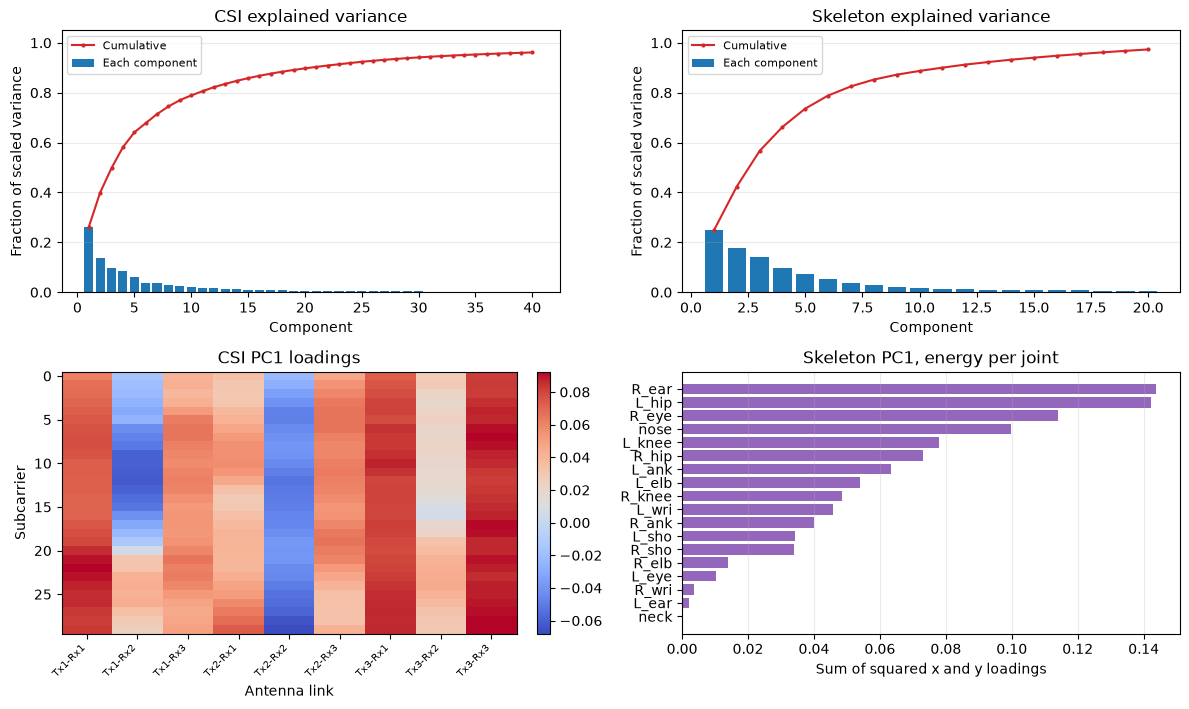

In [15]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7.2))

for ax, model, title in (
    (axes[0, 0], pca_csi, "CSI"),
    (axes[0, 1], pca_skel, "Skeleton"),
):
    ratio = model.explained_variance_ratio_
    index = np.arange(1, len(ratio) + 1)
    ax.bar(index, ratio, color="tab:blue", label="Each component")
    ax.plot(index, np.cumsum(ratio), color="tab:red", marker=".", ms=4, label="Cumulative")
    ax.set_title(f"{title} explained variance")
    ax.set_xlabel("Component")
    ax.set_ylabel("Fraction of scaled variance")
    ax.set_ylim(0, 1.05)
    ax.legend(fontsize=8)
    ax.grid(axis="y", alpha=0.25)

csi_loading = pca_csi.components_[0].reshape(N_SUB, N_LINKS)
image = axes[1, 0].imshow(csi_loading, aspect="auto", cmap="coolwarm")
axes[1, 0].set_title("CSI PC1 loadings")
axes[1, 0].set_xlabel("Antenna link")
axes[1, 0].set_ylabel("Subcarrier")
axes[1, 0].set_xticks(range(N_LINKS))
axes[1, 0].set_xticklabels(LINK_NAMES, rotation=45, ha="right", fontsize=7)
fig.colorbar(image, ax=axes[1, 0], fraction=0.046, pad=0.04)

joint_energy = np.sum(pca_skel.components_[0].reshape(N_JOINTS, 2) ** 2, axis=1)
order = np.argsort(joint_energy)
axes[1, 1].barh(np.arange(N_JOINTS), joint_energy[order], color="tab:purple")
axes[1, 1].set_yticks(np.arange(N_JOINTS))
axes[1, 1].set_yticklabels(np.array(JOINT_NAMES)[order])
axes[1, 1].set_title("Skeleton PC1, energy per joint")
axes[1, 1].set_xlabel("Sum of squared x and y loadings")
axes[1, 1].grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()


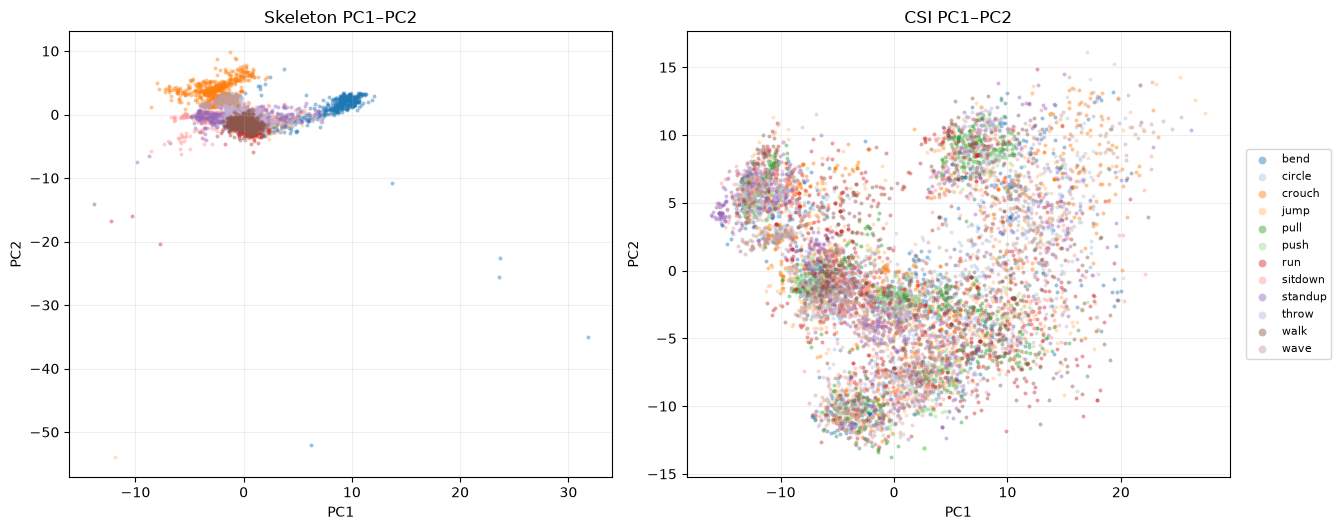

In [16]:
def scatter_pca(ax, scores, pcs, labels, names, title):
    cmap = plt.get_cmap("tab20" if len(names) > 10 else "tab10")
    a, b = pcs
    for i, name in enumerate(names):
        mask = labels == name
        ax.scatter(
            scores[mask, a], scores[mask, b],
            s=8, alpha=0.45, color=cmap(i % cmap.N), label=str(name), linewidths=0,
        )
    ax.set_xlabel(f"PC{a + 1}")
    ax.set_ylabel(f"PC{b + 1}")
    ax.set_title(title)
    ax.grid(alpha=0.2)


rng = np.random.default_rng(RANDOM_STATE)
plot_rows = []
for pose in pose_order:
    candidates = np.flatnonzero(kept_pose == pose)
    take = min(700, len(candidates))
    plot_rows.append(rng.choice(candidates, size=take, replace=False))
plot_rows = np.concatenate(plot_rows)

fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.4))
scatter_pca(axes[0], Z_skel[plot_rows], (0, 1), kept_pose[plot_rows], pose_order, "Skeleton PC1–PC2")
scatter_pca(axes[1], Z_csi[plot_rows], (0, 1), kept_pose[plot_rows], pose_order, "CSI PC1–PC2")
axes[1].legend(loc="center left", bbox_to_anchor=(1.02, 0.5), fontsize=8, markerscale=2)
plt.tight_layout()
plt.show()


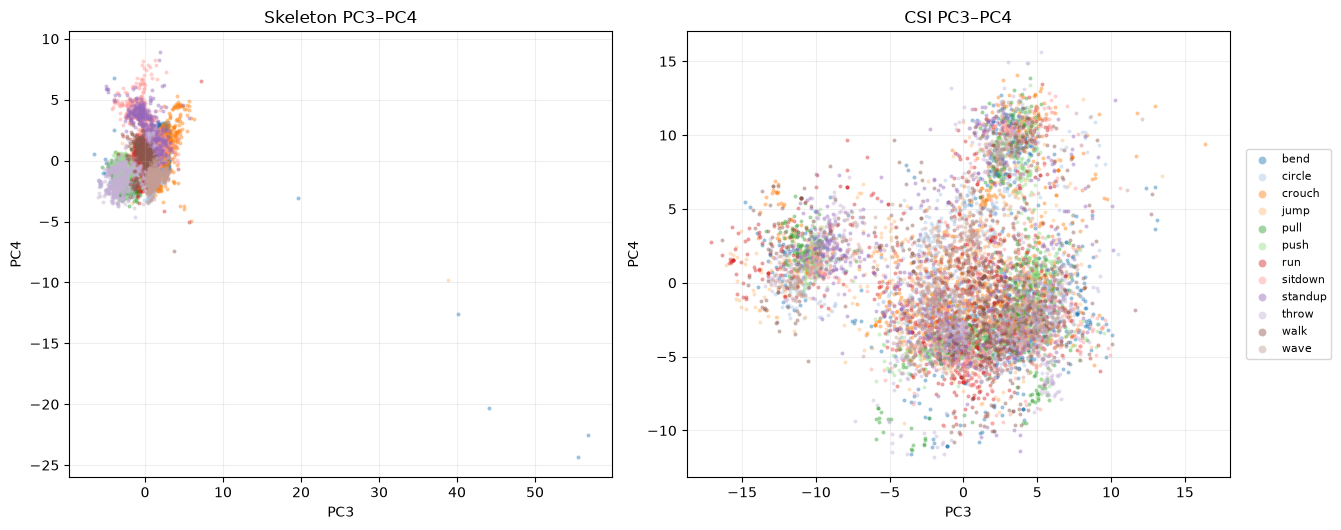

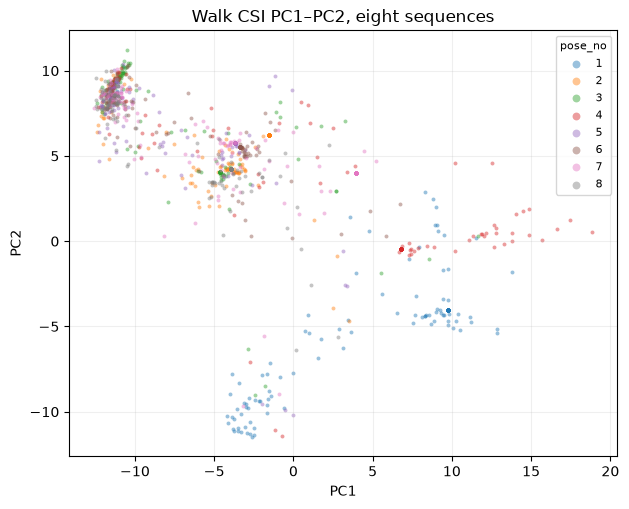

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.4))
scatter_pca(axes[0], Z_skel[plot_rows], (2, 3), kept_pose[plot_rows], pose_order, "Skeleton PC3–PC4")
scatter_pca(axes[1], Z_csi[plot_rows], (2, 3), kept_pose[plot_rows], pose_order, "CSI PC3–PC4")
axes[1].legend(loc="center left", bbox_to_anchor=(1.02, 0.5), fontsize=8, markerscale=2)
plt.tight_layout()
plt.show()

# Within one pose, do the sequences form their own clouds?
walk_sequences = sorted(df.loc[df["pose"] == "walk", "pose_no"].unique())[:8]
walk_mask = (df["pose"].to_numpy() == "walk") & np.isin(df["pose_no"].to_numpy(), walk_sequences) & skel_keep
walk_scores = Z_csi_all[walk_mask]
walk_id = df.loc[walk_mask, "pose_no"].astype(str).to_numpy()

fig, ax = plt.subplots(figsize=(6.4, 5.2))
scatter_pca(ax, walk_scores, (0, 1), walk_id, [str(s) for s in walk_sequences], "Walk CSI PC1–PC2, eight sequences")
ax.legend(title="pose_no", fontsize=8, title_fontsize=8, markerscale=2)
plt.tight_layout()
plt.show()


### Interpretation

CSI needs **34 principal components** to retain 95% of standardized variance, while the normalized skeleton needs 17. More importantly, the first CSI components have a between-class/within-class scatter of only about **0.02–0.03**, compared with **0.64–1.01** for the skeleton.

This means a single CSI frame does not contain a clean pose boundary in its dominant variance directions. The skeleton separates poses because it directly describes body geometry; CSI mainly records the indirect and noisier wireless response. The modeling stage should therefore preserve sequence dynamics instead of classifying isolated frames.

In [18]:
# Hand-off for modeling. df itself is unchanged and still has every frame.
N_KEEP_PCS = 10
pca_frame = df.loc[skel_keep, ["pose", "pose_no", "frame"]].reset_index(drop=True)
for component in range(N_KEEP_PCS):
    pca_frame[f"csi_pc{component + 1}"] = Z_csi[:, component]
    pca_frame[f"skel_pc{component + 1}"] = Z_skel[:, component]

print("Objects for the modeling section")
print(f"  X_csi {X_csi.shape}  packet-averaged amplitude, aligned with df")
print(f"  skel_keep {skel_keep.shape}  frames used for the skeleton PCA")
print(f"  Z_csi {Z_csi.shape}  CSI scores on skel_keep")
print(f"  Z_skel {Z_skel.shape}  skeleton scores on skel_keep")
print(f"  pca_frame {pca_frame.shape}")
display(pca_frame.head())


Objects for the modeling section
  X_csi (132847, 270)  packet-averaged amplitude, aligned with df
  skel_keep (132847,)  frames used for the skeleton PCA
  Z_csi (131411, 40)  CSI scores on skel_keep
  Z_skel (131411, 20)  skeleton scores on skel_keep
  pca_frame (131411, 23)


,pose,pose_no,frame,csi_pc1,skel_pc1,csi_pc2,skel_pc2,csi_pc3,skel_pc3,csi_pc4,...,csi_pc6,skel_pc6,csi_pc7,skel_pc7,csi_pc8,skel_pc8,csi_pc9,skel_pc9,csi_pc10,skel_pc10
0,bend,1,1,10.763373,-0.654092,5.076175,-1.151172,-4.731171,0.556574,-4.932326,...,-5.055630,-0.954702,-2.218268,0.641512,-2.677711,0.067028,1.389086,-0.302989,-1.036889,0.186993
1,bend,1,2,11.709083,-0.833211,5.860432,-1.232573,-4.700882,0.579884,-4.387353,...,-4.556015,-1.006463,-2.850936,0.693623,-3.055704,0.059927,1.764944,-0.277628,-1.423496,0.272127
2,bend,1,3,7.650060,-1.042500,3.753406,-1.305850,-4.702443,0.902351,-5.992215,...,-4.776482,-1.246490,-2.369501,0.674596,-2.176425,-0.137520,0.196615,-0.340683,-2.334996,0.332384
3,bend,1,4,12.219818,-0.929281,5.238952,-1.732687,-6.235730,0.773482,-4.346493,...,-5.104809,-0.409335,-1.961737,0.772627,-3.262169,-0.254840,2.335113,0.001376,-0.839124,0.510954
4,bend,1,5,10.494534,-0.856124,5.677616,-1.296905,-5.778750,0.900561,-2.898083,...,-6.663218,-0.765598,-1.543235,0.782431,-2.289758,0.125166,2.509609,-0.288316,-2.027817,0.395373


## 5. Wavelet Features

### Purpose

PCA describes variation in individual frames, but many labels represent motion over a complete recording. A level-2 Daubechies-4 wavelet decomposes each sequence into:

- `A2`: coarse, slowly changing structure;
- `D2`: medium-scale changes;
- `D1`: short, rapid changes.

The initial wavelet table contains 54 sequence-level energies: three temporal bands and three subcarrier bands for each of the nine antenna links. Mean-square energy is used so features are comparable across unequal sequence lengths.

In [19]:
%pip install -q PyWavelets


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [20]:
import pywt

WAVELET = "db4"
WAVELET_LEVEL = 2
BANDS = ["A2", "D2", "D1"]

def band_energy(signal, level=WAVELET_LEVEL):
    """Mean square of each wavelet band. Mean square does not grow with the trace length."""
    coeffs = pywt.wavedec(np.asarray(signal, dtype=np.float64), WAVELET, level=level)
    return np.array([np.mean(c * c) for c in coeffs], dtype=np.float64)

feature_rows = []
sequence_rows = []
for (pose, pose_no), idx in seq_index.items():
    idx = np.sort(idx)
    cube = X_csi[idx].reshape(len(idx), N_SUB, N_LINKS)  # (frames, 30 subcarriers, 9 links)
    time_energy = [band_energy(cube[:, :, link].mean(axis=1)) for link in range(N_LINKS)]
    spectrum = cube.mean(axis=0)
    freq_energy = [band_energy(spectrum[:, link]) for link in range(N_LINKS)]
    feature_rows.append(np.concatenate(time_energy + freq_energy))
    sequence_rows.append({"pose": pose, "pose_no": int(pose_no), "n_frames": len(idx)})

W = np.vstack(feature_rows)
wave_df = pd.DataFrame(sequence_rows)
feature_names = [
    f"{view}|{link}|{band}"
    for view in ("time", "subcarrier")
    for link in LINK_NAMES
    for band in BANDS
]
print(f"W {W.shape} = sequences x (time bands + subcarrier bands)")
print(f"bands per link, in order: {BANDS}")
display(wave_df.head())


W (1152, 54) = sequences x (time bands + subcarrier bands)
bands per link, in order: ['A2', 'D2', 'D1']


,pose,pose_no,n_frames
0,bend,1,110
1,bend,2,109
2,bend,3,109
3,bend,4,110
4,bend,5,110


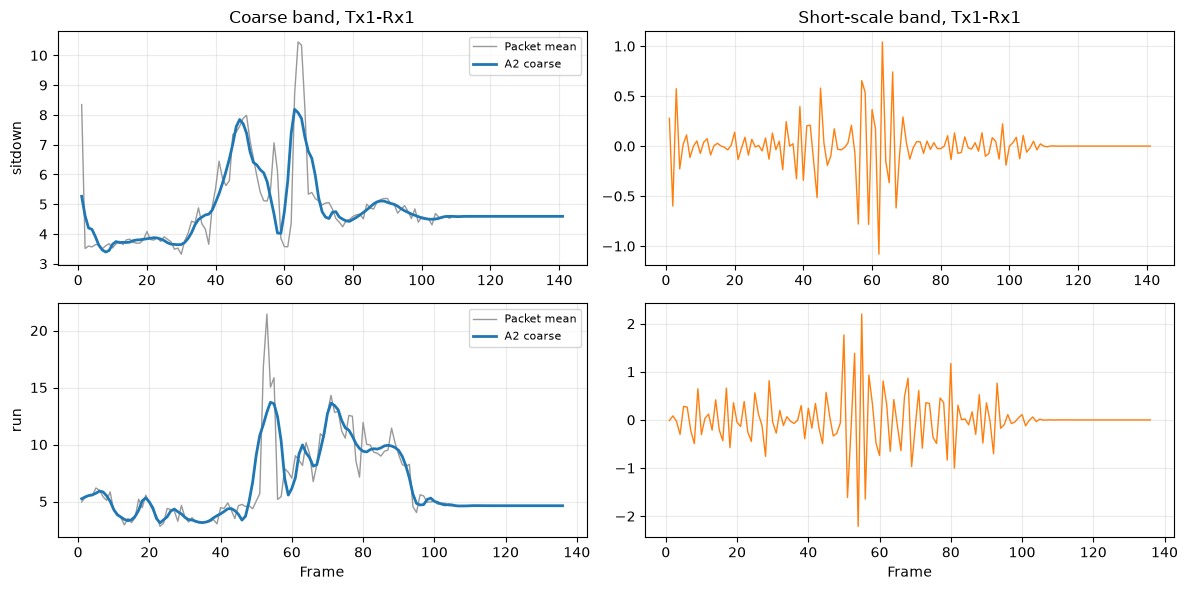

In [21]:
def reconstruct_band(signal, which):
    coeffs = pywt.wavedec(np.asarray(signal, dtype=np.float64), WAVELET, level=WAVELET_LEVEL)
    kept = [coeff if band == which else np.zeros_like(coeff) for band, coeff in zip(BANDS, coeffs)]
    return pywt.waverec(kept, WAVELET)[: len(signal)]

fig, axes = plt.subplots(2, 2, figsize=(12, 6))
for row, pose in enumerate(("sitdown", "run")):
    idx = np.sort(seq_index[(pose, 1)])
    trace = X_csi[idx].reshape(len(idx), N_SUB, N_LINKS)[:, :, 0].mean(axis=1)
    frames = df.loc[idx, "frame"].to_numpy()
    axes[row, 0].plot(frames, trace, color="0.6", lw=1, label="Packet mean")
    axes[row, 0].plot(frames, reconstruct_band(trace, "A2"), color="tab:blue", lw=2, label="A2 coarse")
    axes[row, 1].plot(frames, reconstruct_band(trace, "D1"), color="tab:orange", lw=1)
    axes[row, 0].set_ylabel(pose)
    axes[row, 0].legend(fontsize=8)
    axes[row, 0].grid(alpha=0.25)
    axes[row, 1].grid(alpha=0.25)
axes[0, 0].set_title("Coarse band, Tx1-Rx1")
axes[0, 1].set_title("Short-scale band, Tx1-Rx1")
axes[1, 0].set_xlabel("Frame")
axes[1, 1].set_xlabel("Frame")
plt.tight_layout()
plt.show()


In [22]:
# Pose labels score the features here. They are not used to build W.
pose_of_seq = wave_df["pose"].to_numpy()
separation_rows = []
for j, name in enumerate(feature_names):
    column = W[:, j]
    center = column.mean()
    between = 0.0
    for pose in pose_order:
        mask = pose_of_seq == pose
        between += mask.sum() * (column[mask].mean() - center) ** 2
    total = np.sum((column - center) ** 2)
    separation_rows.append({"feature": name, "between_pose_share": between / total})

separation = pd.DataFrame(separation_rows).sort_values("between_pose_share", ascending=False)
print("Wavelet bands whose energy differs most across poses")
display(separation.head(10).reset_index(drop=True))


Wavelet bands whose energy differs most across poses


,feature,between_pose_share
0,time|Tx2-Rx3|D1,0.299028
1,time|Tx1-Rx1|D1,0.240966
2,time|Tx3-Rx3|D2,0.234212
3,time|Tx2-Rx3|D2,0.211766
4,time|Tx3-Rx3|D1,0.209137
5,time|Tx1-Rx3|D1,0.207468
6,time|Tx1-Rx1|D2,0.198892
7,time|Tx1-Rx3|D2,0.198374
8,time|Tx2-Rx1|D1,0.172406
9,subcarrier|Tx1-Rx3|D2,0.168650


### Interpretation

The features that differ most across poses are mainly the temporal **D1 and D2 bands**, especially on Tx2–Rx3, Tx1–Rx1, and Tx3–Rx3. This indicates that pose information is carried more by short- and medium-scale motion than by the coarse absolute channel level.

However, the best single feature explains only about **30% of its variation between pose classes**. No individual wavelet energy is sufficient; a classifier must combine several links and time scales.

## 6. Unsupervised Baselines: K-means and GMM

### Purpose

This section asks whether the 54 wavelet energies naturally form 12 groups without seeing pose labels. Features are standardized before fitting:

- **K-means**, which favors compact, roughly spherical clusters;
- **Diagonal Gaussian Mixture Model (GMM)**, which allows different feature spreads and soft membership.

Adjusted Rand Index (ARI), normalized mutual information, and majority-vote purity compare the discovered groups with known poses. These are descriptive agreement scores on the same sequences, not held-out prediction accuracy.

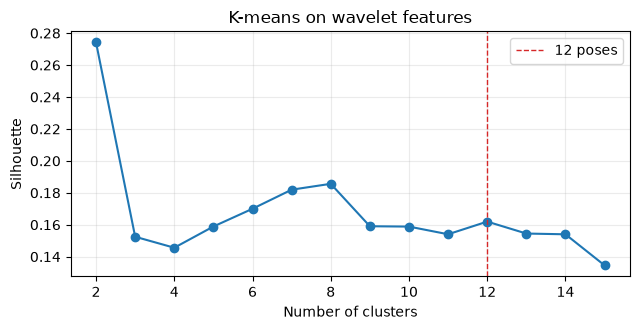

,method,adjusted Rand,normalized mutual information,majority-vote purity
0,K-means,0.031,0.140,0.185
1,GMM diag,0.052,0.172,0.205


GMM converged: True
Mean maximum responsibility: 1.00


In [23]:
import warnings
from sklearn.cluster import KMeans
warnings.filterwarnings(
    "ignore",
    message="KMeans is known to have a memory leak",
    category=UserWarning,
)
from sklearn.mixture import GaussianMixture
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score, silhouette_score

scaler_wave = StandardScaler()
W_scaled = scaler_wave.fit_transform(W)
y_pose = wave_df["pose"].to_numpy()

silhouettes = []
for k in range(2, 16):
    trial = KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE)
    trial_labels = trial.fit_predict(W_scaled)
    silhouettes.append({"k": k, "silhouette": silhouette_score(W_scaled, trial_labels)})
silhouettes = pd.DataFrame(silhouettes)

fig, ax = plt.subplots(figsize=(6.5, 3.4))
ax.plot(silhouettes["k"], silhouettes["silhouette"], marker="o")
ax.axvline(12, color="tab:red", ls="--", lw=1, label="12 poses")
ax.set_xlabel("Number of clusters")
ax.set_ylabel("Silhouette")
ax.set_title("K-means on wavelet features")
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

kmeans = KMeans(n_clusters=12, n_init=20, random_state=RANDOM_STATE)
km_labels = kmeans.fit_predict(W_scaled)

gmm = GaussianMixture(
    n_components=12,
    covariance_type="diag",
    n_init=5,
    random_state=RANDOM_STATE,
)
gmm_labels = gmm.fit_predict(W_scaled)
responsibility = gmm.predict_proba(W_scaled)

def cluster_purity(y_true, y_pred):
    table = pd.crosstab(y_pred, y_true)
    return table.max(axis=1).sum() / len(y_true)

score_table = pd.DataFrame({
    "method": ["K-means", "GMM diag"],
    "adjusted Rand": [
        adjusted_rand_score(y_pose, km_labels),
        adjusted_rand_score(y_pose, gmm_labels),
    ],
    "normalized mutual information": [
        normalized_mutual_info_score(y_pose, km_labels),
        normalized_mutual_info_score(y_pose, gmm_labels),
    ],
    "majority-vote purity": [
        cluster_purity(y_pose, km_labels),
        cluster_purity(y_pose, gmm_labels),
    ],
})
display(score_table.round(3))
print(f"GMM converged: {bool(gmm.converged_)}")
print(f"Mean maximum responsibility: {responsibility.max(axis=1).mean():.2f}")


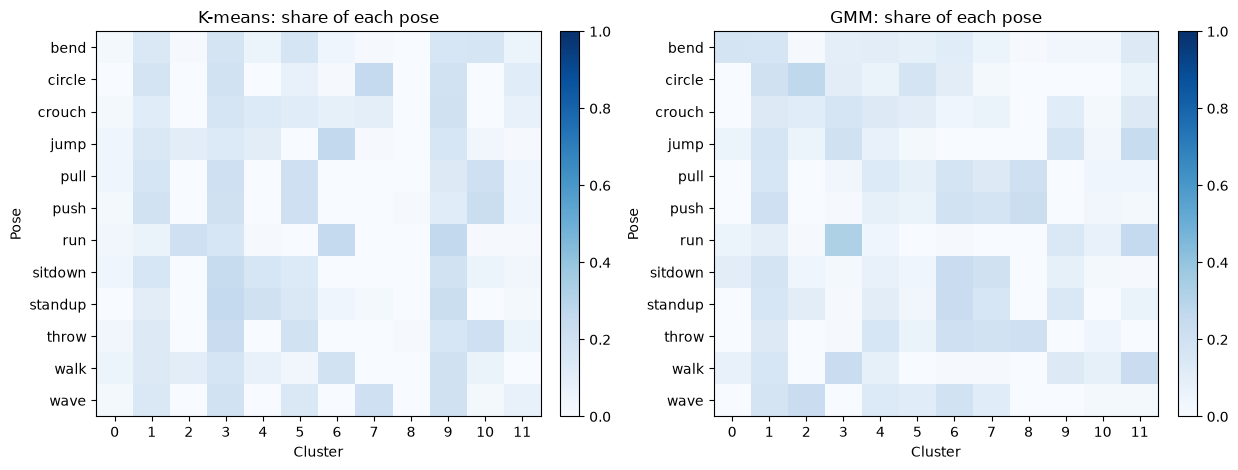

wave_df rows match W, km_labels, and gmm_labels


,pose,pose_no,n_frames,kmeans,gmm
0,bend,1,110,7,2
1,bend,2,109,3,6
2,bend,3,109,3,6
3,bend,4,110,3,6
4,bend,5,110,3,6


In [24]:
def pose_cluster_share(y_true, y_pred):
    table = pd.crosstab(pd.Series(y_true, name="pose"), pd.Series(y_pred, name="cluster"))
    return table.div(table.sum(axis=1), axis=0).reindex(index=pose_order)

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.8))
for ax, labels, title in (
    (axes[0], km_labels, "K-means"),
    (axes[1], gmm_labels, "GMM"),
):
    share = pose_cluster_share(y_pose, labels)
    image = ax.imshow(share.to_numpy(), vmin=0, vmax=1, cmap="Blues", aspect="auto")
    ax.set_title(f"{title}: share of each pose")
    ax.set_xlabel("Cluster")
    ax.set_ylabel("Pose")
    ax.set_yticks(range(len(pose_order)))
    ax.set_yticklabels(pose_order)
    ax.set_xticks(range(share.shape[1]))
    fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()

wave_df = wave_df.copy()
wave_df["kmeans"] = km_labels
wave_df["gmm"] = gmm_labels
print("wave_df rows match W, km_labels, and gmm_labels")
display(wave_df.head())


### Interpretation

The unsupervised groups do **not** recover the 12 pose labels. K-means reaches ARI 0.031 and purity 0.185; the GMM is only slightly better at ARI 0.052 and purity 0.205. A confident GMM assignment (mean maximum responsibility near 1.00) does not contradict this result: the model is confident about clusters that represent some other structure, such as recording conditions or overall channel strength.

This is evidence for using supervised learning and for retaining more temporal order. Collapsing a whole movement into band energies loses distinctions such as opposite movement direction.

### What to carry into modeling

Use the CSI side as the model input and `pose` as the target.

- `X_csi` is the 270-dimensional packet average, aligned with `df`. `Z_csi` is that matrix after standardization and PCA, on the frames in `skel_keep`.
- `W` is the 54 wavelet energies, one row per sequence, aligned with `wave_df`. `km_labels` and `gmm_labels` are the 12-group assignments for those same rows.

The skeleton scores are a view of the annotation. They show that the 12 pose names have geometric structure. They are not a Wi-Fi feature: a model that sees the skeleton and predicts `pose` is reading the label.

The cluster scores measure agreement with the pose names on the same sequences. They are not a held-out accuracy. When the data are split, keep every `(pose, pose_no)` sequence entirely in train or entirely in test, and fit `StandardScaler` on the training sequences only. Frames inside one sequence are neighbors, so a random frame split leaks the same recording into both sides.


# 3. Model Training and Evaluation

## Prediction task

One complete CSI recording is mapped to one of 12 pose labels. The model sees packet-averaged CSI only; skeleton coordinates remain a diagnostic annotation and are never included in the predictors.

## Feature design

For each of the nine antenna links, the 30 highly correlated subcarriers are averaged into one time trace. Six motion features are then calculated per link:

1. level-2 wavelet energy in `A2`, `D2`, and `D1`;
2. standard deviation of frame-to-frame change;
3. `D1` energy in the first half and second half of the sequence.

This produces 9 × 6 = **54 features per sequence**. Splitting the sequence into halves retains a small amount of ordering information, which helps distinguish reversed motions such as sitting down and standing up.

## Models and leakage control

- **Logistic regression** provides a regularized, interpretable linear baseline.
- **Random forest** tests whether nonlinear feature combinations help.

The last 20 available sequence identifiers are held out for testing, leaving 76 sequences per pose for training and 20 per pose for testing. Hyperparameter tuning, model selection, and scaling use training folds only; the held-out set is used once for final reporting. This is a stricter and more realistic evaluation than a random frame split.

## Evaluation metrics

Accuracy measures total correctness, while macro-F1 gives every pose equal weight. The confusion matrix and per-class recall reveal which motion types remain unresolved. Chance accuracy is 1/12, or 8.3%.

In [28]:
def d1_energy(signal):
    """Mean square of the shortest wavelet band. Level 1 is D1, and it fits a half sequence."""
    coeffs = pywt.wavedec(np.asarray(signal, dtype=np.float64), WAVELET, level=1)
    return float(np.mean(coeffs[-1] * coeffs[-1]))

def drop_repeated_frames(cube):
    """Drop a frame whose packet-averaged CSI is an exact copy of the previous one.

    Recordings freeze on a copied frame at the end. That repeated frame is the same
    still ending in every pose, so it flattens the second half of the motion.
    """
    flat = cube.reshape(len(cube), -1)
    changed = np.ones(len(cube), dtype=bool)
    changed[1:] = np.max(np.abs(flat[1:] - flat[:-1]), axis=1) > 0
    if changed.sum() < 8:
        return cube, 0
    return cube[changed], int((~changed).sum())


motion_rows = []
motion_meta = []
for (pose, pose_no), idx in seq_index.items():
    idx = np.sort(idx)
    cube = X_csi[idx].reshape(len(idx), N_SUB, N_LINKS)
    cube, n_repeated = drop_repeated_frames(cube)
    parts = []
    for link in range(N_LINKS):
        trace = cube[:, :, link].mean(axis=1)
        coarse = band_energy(trace)  # A2, D2, D1 on the kept frames
        step = float(np.std(np.diff(trace)))
        mid = len(trace) // 2
        parts.append([
            coarse[0], coarse[1], coarse[2],
            step,
            d1_energy(trace[:mid]),
            d1_energy(trace[mid:]),
        ])
    motion_rows.append(np.concatenate(parts))
    motion_meta.append({
        "pose": pose,
        "pose_no": int(pose_no),
        "n_frames": len(idx),
        "n_repeated": n_repeated,
    })

X_motion = np.vstack(motion_rows)
motion_df = pd.DataFrame(motion_meta)
motion_names = [
    f"{link}|{part}"
    for link in LINK_NAMES
    for part in ("A2", "D2", "D1", "step", "D1_first_half", "D1_second_half")
]
print(f"X_motion {X_motion.shape} = sequences x (9 links x 6 motion numbers)")
print(
    f"Repeated frames removed: {motion_df['n_repeated'].sum():,} "
    f"(mean {motion_df['n_repeated'].mean():.1f} per sequence, "
    f"median {motion_df['n_repeated'].median():.0f})"
)


X_motion (1152, 54) = sequences x (9 links x 6 motion numbers)
Repeated frames removed: 13,581 (mean 11.8 per sequence, median 5)


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix
from sklearn.pipeline import Pipeline

label_order = sorted(motion_df["pose"].unique())
sequence_ids = sorted(motion_df["pose_no"].unique())
test_ids = set(sequence_ids[-20:])
test_mask = motion_df["pose_no"].isin(test_ids).to_numpy()
train_mask = ~test_mask

X_train, X_test = X_motion[train_mask], X_motion[test_mask]
y_train = motion_df.loc[train_mask, "pose"].to_numpy()
y_test = motion_df.loc[test_mask, "pose"].to_numpy()

print(
    f"Held-out sequence numbers: {min(test_ids)}–{max(test_ids)} "
    f"({len(test_ids)} identifiers, including gaps)"
)
print(f"Train: {len(y_train)} sequences ({len(y_train) / len(label_order):.0f} per pose)")
print(f"Test:  {len(y_test)} sequences ({len(y_test) / len(label_order):.0f} per pose)")

# Tune logistic regression without looking at the held-out test sequences.
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
c_rows = []
for regularization in np.logspace(-2, 2, 9):
    candidate = Pipeline([
        ("scaler", StandardScaler()),
        ("clf", LogisticRegression(
            C=regularization,
            max_iter=4000,
            random_state=RANDOM_STATE,
        )),
    ])
    scores = cross_val_score(candidate, X_train, y_train, cv=cv, scoring="f1_macro")
    c_rows.append({
        "C": regularization,
        "cv_macro_f1": scores.mean(),
        "cv_std": scores.std(),
    })

c_table = pd.DataFrame(c_rows).sort_values("cv_macro_f1", ascending=False)
best_C = float(c_table.iloc[0]["C"])
print(f"Best logistic-regression C from training CV: {best_C:g}")
display(c_table.round(3).reset_index(drop=True))

logit = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(
        C=best_C,
        max_iter=4000,
        random_state=RANDOM_STATE,
    )),
])
forest = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", RandomForestClassifier(
        n_estimators=400,
        max_depth=8,
        min_samples_leaf=4,
        random_state=RANDOM_STATE,
        n_jobs=-1,
    )),
])

# Select the model with training CV only. The test set remains untouched.
forest_cv = cross_val_score(forest, X_train, y_train, cv=cv, scoring="f1_macro")
selection_table = pd.DataFrame({
    "model": ["logistic regression", "random forest"],
    "cv_macro_f1": [c_table.iloc[0]["cv_macro_f1"], forest_cv.mean()],
    "cv_std": [c_table.iloc[0]["cv_std"], forest_cv.std()],
}).sort_values("cv_macro_f1", ascending=False)
pose_model_name = selection_table.iloc[0]["model"]
print("Model selection on training folds")
display(selection_table.round(3).reset_index(drop=True))

logit.fit(X_train, y_train)
forest.fit(X_train, y_train)

def evaluate_model(model, name):
    """Return train/test metrics and held-out predictions for one fitted model."""
    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)
    metrics = {
        "model": name,
        "train_accuracy": accuracy_score(y_train, train_pred),
        "test_accuracy": accuracy_score(y_test, test_pred),
        "train_macro_f1": f1_score(
            y_train, train_pred, average="macro", labels=label_order
        ),
        "test_macro_f1": f1_score(
            y_test, test_pred, average="macro", labels=label_order
        ),
    }
    return metrics, test_pred


logit_scores, logit_pred = evaluate_model(logit, "logistic regression")
forest_scores, forest_pred = evaluate_model(forest, "random forest")
score_table = pd.DataFrame([logit_scores, forest_scores])
display(score_table.round(3))

if pose_model_name == "logistic regression":
    pose_model, pose_pred = logit, logit_pred
else:
    pose_model, pose_pred = forest, forest_pred

print(f"Selected from training CV: {pose_model_name}")
print(f"Chance accuracy: {1 / len(label_order):.1%}")

In [ ]:
cm = confusion_matrix(y_test, pose_pred, labels=label_order)
recall = pd.Series(np.diag(cm) / cm.sum(axis=1), index=label_order).sort_values()
share = cm / cm.sum(axis=1, keepdims=True)

fig, ax = plt.subplots(figsize=(7.2, 6.2))
image = ax.imshow(share, vmin=0, vmax=1, cmap="Blues")
ax.set_xticks(range(len(label_order)))
ax.set_yticks(range(len(label_order)))
ax.set_xticklabels(label_order, rotation=45, ha="right")
ax.set_yticklabels(label_order)
ax.set_xlabel("Predicted pose")
ax.set_ylabel("True pose")
ax.set_title(f"{pose_model_name}: share of each true pose")
fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()

print("Lowest test recall")
print(recall.head(3).map(lambda v: f"{v:.1%}").to_string())

if pose_model_name == "logistic regression":
    weight = np.mean(np.abs(pose_model.named_steps["clf"].coef_), axis=0)
    weight_name = "mean |coefficient|"
else:
    weight = pose_model.named_steps["clf"].feature_importances_
    weight_name = "impurity importance"
importance = pd.DataFrame({"feature": motion_names, weight_name: weight})
importance = importance.sort_values(weight_name, ascending=False)
print(f"Strongest {pose_model_name} features")
display(importance.head(12).reset_index(drop=True))

motion_df = motion_df.copy()
motion_df["split"] = np.where(train_mask, "train", "test")
motion_df.loc[test_mask, "predicted"] = pose_pred
print(f"pose_model is the fitted {pose_model_name}. Test predictions are in motion_df['predicted'].")


### Interpretation

In the recorded run, logistic regression produced the better held-out result: **30.0% accuracy and 27.0% macro-F1**, compared with 15.8% accuracy and 11.4% macro-F1 for the random forest. Both exceed the 8.3% chance accuracy, so CSI contains pose-related information, but the result is not yet strong enough for reliable deployment. The revised code selects the final model from training-fold cross-validation rather than from these test scores.

The forest's training accuracy of **97.5%** falls to **15.8%** on the test set, which is clear overfitting. Logistic regression also has a train–test gap (60.1% vs. 30.0%) but generalizes substantially better.

The hardest classes are jump (0% recall), stand-up (5%), and sit-down (10%). These movements likely require finer temporal order than six summary features retain. The strongest coefficients emphasize frame-to-frame change and high-frequency `D1` energy, supporting the earlier conclusion that rapid dynamics matter more than static amplitude.

### Recommended next experiment

Use a 1D temporal convolutional network or a small recurrent model on the nine link traces with sequence masking. Compare it against this logistic baseline using the same held-out sequence identifiers. If the goal is generalization to new people or rooms, the split must also hold out subjects or environments; the current result measures generalization only to later recording identifiers in this dataset.

# 4. Inference and Practical Use

The functions below apply the same preprocessing and feature extraction used during training. A new input may be either raw CSI with shape `(frames, 5, 30, 3, 3)` or packet-averaged CSI with shape `(frames, 30, 3, 3)` / `(frames, 30, 9)`.

Inference must reuse the fitted pipeline because its scaler contains statistics learned from the training split. Refitting the scaler on a test sequence would leak information and change the feature coordinate system.

In [ ]:
def prepare_csi_sequence(csi_sequence):
    """Convert raw or packet-averaged CSI into a (frames, 30, 9) amplitude cube."""
    sequence = np.asarray(csi_sequence)

    if sequence.ndim == 5 and sequence.shape[1:] == (N_PKT, N_SUB, N_TX, N_RX):
        sequence = np.abs(sequence).mean(axis=1)
    elif sequence.ndim == 4 and sequence.shape[1:] == (N_SUB, N_TX, N_RX):
        sequence = np.abs(sequence)
    elif sequence.ndim == 3 and sequence.shape[1:] == (N_SUB, N_LINKS):
        sequence = np.abs(sequence)
    else:
        raise ValueError(
            "Expected (frames, 5, 30, 3, 3), (frames, 30, 3, 3), "
            "or (frames, 30, 9); received " + str(sequence.shape)
        )

    if sequence.shape[0] < 8:
        raise ValueError("At least eight frames are required for wavelet features")

    return sequence.reshape(len(sequence), N_SUB, N_LINKS).astype(np.float32)


def extract_motion_features(csi_sequence):
    """Create the 54-feature sequence descriptor used by the trained classifiers."""
    cube = prepare_csi_sequence(csi_sequence)
    cube, _ = drop_repeated_frames(cube)

    link_features = []
    for link in range(N_LINKS):
        trace = cube[:, :, link].mean(axis=1)
        wavelet_energy = band_energy(trace)
        midpoint = len(trace) // 2
        link_features.extend([
            wavelet_energy[0],
            wavelet_energy[1],
            wavelet_energy[2],
            float(np.std(np.diff(trace))),
            d1_energy(trace[:midpoint]),
            d1_energy(trace[midpoint:]),
        ])

    return np.asarray(link_features, dtype=np.float64)


def predict_pose(csi_sequence, model=pose_model):
    """Return the predicted pose and class probabilities for one CSI sequence."""
    features = extract_motion_features(csi_sequence).reshape(1, -1)
    predicted = model.predict(features)[0]
    result = pd.DataFrame({
        "pose": model.classes_,
        "probability": model.predict_proba(features)[0],
    }).sort_values("probability", ascending=False, ignore_index=True)
    return predicted, result


# Example using a sequence already loaded in this notebook:
# example_idx = np.sort(seq_index[("walk", 1)])
# predicted_pose, probabilities = predict_pose(X_csi[example_idx].reshape(-1, N_SUB, N_LINKS))
# print("Predicted pose:", predicted_pose)
# display(probabilities.head())

## Final conclusions

1. The dataset is balanced by sequence, but sequence lengths vary and must be handled explicitly.
2. Adjacent subcarriers are highly redundant, while antenna links retain complementary information.
3. Skeleton geometry separates poses well, but it is annotation rather than a valid Wi-Fi predictor.
4. Static CSI PCA and unsupervised wavelet clusters do not recover pose classes.
5. Supervised temporal summaries perform above chance, with logistic regression reaching 30% held-out accuracy.
6. Poor recall on directional movements shows that the next model should retain the complete time order.

The current classifier is a useful baseline and analysis tool, not a production-ready pose detector. Its main value is demonstrating that motion-sensitive CSI features carry real pose information while also identifying where temporal information is being lost.